**关于注意力可视化热力图**

In [ ]:
import torch
from d2l import torch as d2l

def show_heatmaps(matrices, xlabel, ylabel, titles=None, figsize=(2.5, 2.5),
                  cmap='Reds'):
    """显示矩阵热图"""
    d2l.use_svg_display()
    num_rows, num_cols = matrices.shape[0], matrices.shape[1]
    fig, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize,
                                 sharex=True, sharey=True, squeeze=False)
    for i, (row_axes, row_matrices) in enumerate(zip(axes, matrices)):
        for j, (ax, matrix) in enumerate(zip(row_axes, row_matrices)):
            pcm = ax.imshow(matrix.detach().numpy(), cmap=cmap)
            if i == num_rows - 1:
                ax.set_xlabel(xlabel)
            if j == 0:
                ax.set_ylabel(ylabel)
            if titles:
                ax.set_title(titles[j])
    fig.colorbar(pcm, ax=axes, shrink=0.6);
    d2l.plt.show()


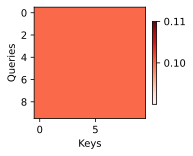

In [3]:
# ① 均匀关注（相当于平均汇聚）
attention_weights = torch.ones(10, 10).reshape((1, 1, 10, 10)) / 10
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')

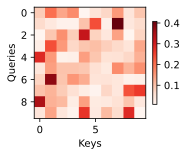

In [2]:
# ② 随机注意力（每行做 softmax 保证和为1）
attention_weights = torch.softmax(torch.randn(10, 10), dim=-1).reshape((1, 1, 10, 10))
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')

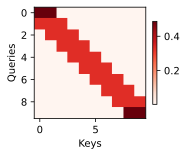

In [5]:
# ③ 局部关注（只看邻近位置，类似卷积的感受野）
mask = torch.eye(10) + torch.diag(torch.ones(9), 1) + torch.diag(torch.ones(9), -1)
attention_weights = torch.softmax(mask * 5, dim=-1).reshape((1, 1, 10, 10))
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')

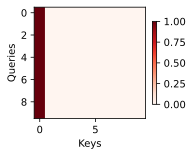

In [6]:
# ④ 只看第一个 token（类似 BERT 的 [CLS] 聚合）
attention_weights = torch.zeros(10, 10)
attention_weights[:, 0] = 1.0
attention_weights = attention_weights.reshape((1, 1, 10, 10))
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')